# Augmentation

> Pretrain the CNN on OSSL with random instrument-like perturbations of the raw spectra, and test whether it then transfers better to Fukushima

In [ ]:
#| default_exp augment

In [ ]:
#| export
import math
import numpy as np, pandas as pd, torch
import torch.nn.functional as F
from scipy.signal import savgol_filter
from fasttransform import Transform
from fastai.torch_core import set_seed, retain_type
import fastai.callback.schedule
from soilspecdl.all import get_spectral_dls, get_splitter, spectral_learner, BatchSNV, TensorSpectrum
from ossl_fuku_transfer.data import shared_wns
from ossl_fuku_transfer.transfer import new_model, model_dir, load_pretrained

/Users/franckalbinet/pro/dev/soilspec/ossl-fuku-transfer/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [ ]:
import matplotlib.pyplot as plt
from fastcore.test import *
from soilspecdata.all import load_ossl
from ossl_fuku_transfer.data import *
from ossl_fuku_transfer.transfer import *
from ossl_fuku_transfer.inside import layer_features, probe

`12_wetchem` and `13_epo` found that the zero-shot failure lies in the Fukushima spectra, and that linear corrections don't fix it. Augmentation takes the other route: it trains the CNN on OSSL spectra perturbed in the ways that `05_paired` measured between instruments, so that the features it learns change less under such differences.

The perturbations act on raw absorbance, before SNV and the derivative. So in training, SNV and the derivative run on each batch, after the perturbations. At prediction, the spectra are preprocessed offline as before.

The module part uses small random arrays, so it runs without the data. The sections from *Data* onwards read OSSL and the Fukushima data, and are marked `#| fukudata`.

## Preprocessing on batches

`SNVDeriv` applies SNV, then the Savitzky-Golay filter, to each spectrum of a batch, as `preprocessings()['snv_d1']` does offline. The filter is linear, so it is a matrix: filtering the rows of an identity matrix with SciPy gives it, edges included, and a matrix product applies it on the GPU.

In [ ]:
#| export
class SNVDeriv(Transform):
    "SNV, then the Savitzky-Golay filter, on each spectrum of a batch, as `preprocessings()['snv_d1']`"
    order = -1
    def __init__(
        self,
        n, # Number of wavenumbers
        window_length=15, # As in `SavitzkyGolay`
        polyorder=3, # As in `SavitzkyGolay`
        deriv=1, # As in `SavitzkyGolay`
    ): self.R = torch.tensor(savgol_filter(np.eye(n), window_length, polyorder, deriv), dtype=torch.float32)
    def encodes(self, x:TensorSpectrum):
        c = x - x.mean(-1, keepdim=True)
        return retain_type((c / (c.std(-1, unbiased=False, keepdim=True) + 1e-10)) @ self.R.to(x.device), x)

In [ ]:
rng = np.random.default_rng(0)
X_syn = 1 + 0.3 * rng.random((6, len(shared_wns)))
xb = TensorSpectrum(torch.tensor(X_syn, dtype=torch.float32).unsqueeze(1), wns=shared_wns)
out = SNVDeriv(len(shared_wns))(xb)
test_eq(type(out), TensorSpectrum)
test_close(out.squeeze(1).numpy(), preprocessings()['snv_d1'].fit_transform(X_syn), eps=1e-4)

## Perturbations

`SpectralAug` perturbs raw absorbance spectra of training batches. Each perturbation applies to each spectrum with probability `p`, with a random size drawn from its range:

- Gaussian broadening with a standard deviation up to `sigma` points. On the 2 cm⁻¹ grid, 3 points is 6 cm⁻¹, the largest broadening tested in `05_paired`.
- A shift along the wavenumber axis of up to `shift` points, by linear interpolation. `05_paired` measured 1.6 cm⁻¹, or 0.8 points.
- A contrast change: absorbance, clipped at 10⁻³, raised to a power between `gamma[0]` and `gamma[1]`, drawn on a log scale. `05_paired` found about six times less contrast in the Thermo spectra, which SNV does not fully remove.
- A baseline: a constant, a slope and a curvature across the spectrum, each up to `baseline` times the spectrum's standard deviation.
- Gaussian noise with a standard deviation of `noise` times the spectrum's standard deviation.

Scaling a whole spectrum is left out, because SNV removes it. As a fastai transform with `split_idx = 0`, it leaves validation batches unchanged.

In [ ]:
#| export
class SpectralAug(Transform):
    "Random broadening, shift, contrast, baseline and noise of raw absorbance spectra, on training batches only"
    split_idx, order = 0, -2
    def __init__(
        self,
        p=0.5, # Probability of each perturbation, per spectrum
        sigma=3., # Largest Gaussian broadening, in points
        shift=1., # Largest shift, in points
        gamma=(0.5, 2.), # Range of the contrast exponent
        baseline=0.2, # Largest baseline term, relative to the spectrum's standard deviation
        noise=0.005, # Noise standard deviation, relative to the spectrum's standard deviation
    ):
        self.p, self.sigma, self.shift, self.gamma, self.baseline, self.noise = p, sigma, shift, gamma, baseline, noise
    def encodes(self, x:TensorSpectrum):
        bs, _, L = x.shape
        dev, y = x.device, torch.as_tensor(x).float()
        on = lambda: torch.rand(bs, 1, 1, device=dev) < self.p
        sig = torch.rand(bs, device=dev) * self.sigma * on().view(bs)
        r = torch.arange(-9, 10, device=dev).float()
        k = torch.exp(-0.5 * (r[None] / sig.clamp(min=1e-3)[:, None])**2)
        k = torch.where(sig[:, None] > 1e-2, k / k.sum(1, keepdim=True), (r[None] == 0).float())
        y = F.conv1d(F.pad(y.view(1, bs, L), (9, 9), mode='replicate'), k[:, None], groups=bs).view(bs, 1, L)
        pos = (torch.arange(L, device=dev).float()[None, None] + (2 * torch.rand(bs, 1, 1, device=dev) - 1) * self.shift * on()).clamp(0, L - 1)
        lo = pos.floor().long()
        w = pos - lo
        y = y.gather(2, lo) * (1 - w) + y.gather(2, (lo + 1).clamp(max=L - 1)) * w
        g = torch.exp(torch.empty(bs, 1, 1, device=dev).uniform_(math.log(self.gamma[0]), math.log(self.gamma[1])))
        y = torch.where(on(), y.clamp(min=1e-3)**g, y)
        sd, t = y.std(-1, keepdim=True), torch.linspace(-1, 1, L, device=dev)[None, None]
        c = (2 * torch.rand(bs, 3, 1, device=dev) - 1) * self.baseline
        y = y + on() * sd * (c[:, :1] + c[:, 1:2] * t + c[:, 2:] * t**2)
        y = y + on() * sd * self.noise * torch.randn_like(y)
        return retain_type(y, x)

In [ ]:
aug = SpectralAug()
set_seed(0)
xa = aug(xb, split_idx=0)
test_eq((type(xa), xa.shape), (TensorSpectrum, xb.shape))
test_eq(torch.allclose(xa, xb), False)
test_eq(torch.equal(aug(xb, split_idx=1), xb), True)
test_close(SpectralAug(p=0)(xb, split_idx=0), xb, eps=1e-5)

`pretrain_aug` trains `new_model` on raw OSSL spectra as `pretrain` does on preprocessed ones, with `aug`, `SNVDeriv` and `BatchSNV` on each batch. The saved model takes spectra preprocessed offline, like the other pretrained models, and loads with `load_pretrained`:

In [ ]:
#| export
def pretrain_aug(
    X, # Raw OSSL absorbance spectra on `shared_wns`
    y, # Targets, such as `log1p` of a soil property
    fname, # File name for the weights, without extension
    aug=None, # Augmentation transform, such as `SpectralAug()`; none if None
    seed=42, # Seed for the validation split and the training
    epochs=20, # Number of one-cycle epochs
    lr=1e-3, # Maximum learning rate
):
    "Train `new_model` on augmented spectra, or load the weights that an earlier run saved under `fname`"
    fn = model_dir()/f'{fname}.pth'
    if not fn.exists():
        set_seed(seed)
        tfms = ([aug] if aug else []) + [SNVDeriv(X.shape[1]), BatchSNV()]
        dls, _ = get_spectral_dls(X, y, shared_wns, splitter=get_splitter(0.9, 0.1, seed=seed), batch_tfms=tfms)
        learn = spectral_learner(dls, new_model())
        with learn.no_bar(), learn.no_logging(): learn.fit_one_cycle(epochs, lr_max=lr)
        torch.save(learn.model.state_dict(), fn)
        pd.DataFrame(learn.recorder.values, columns=learn.recorder.metric_names[1:-1]).to_csv(fn.with_suffix('.csv'), index_label='epoch')
    return load_pretrained(fname)

## Data

OSSL Kex and the Fukushima spectra, as in `03_kex`. The OSSL spectra stay raw for pretraining:

In [ ]:
#| fukudata
om = load_ossl().mir(wmin=shared_wns[0], wmax=shared_wns[-1])
Xo, yo, _ = om.xy('k.ext_usda.a725_cmolc.kg')
yo = np.log1p(yo.ravel())
fuku = load_fuku()
fuku.source = fuku.source.assign(target=fuku.source['soil_ex_K2O'] / mg_k2o_per_cmolc)
Xf, yf, idf = fuku.xy('target')
yf = np.log1p(yf.ravel())
is_test = np.isin(idf, cs137_split()[1])
pipe = preprocessings()['snv_d1']
Xf_d = pipe.transform(Xf)
Xo.shape, Xf_d.shape

((57674, 1675), (1388, 1675))

Three OSSL spectra, raw and after augmentation, then both after SNV and the derivative:

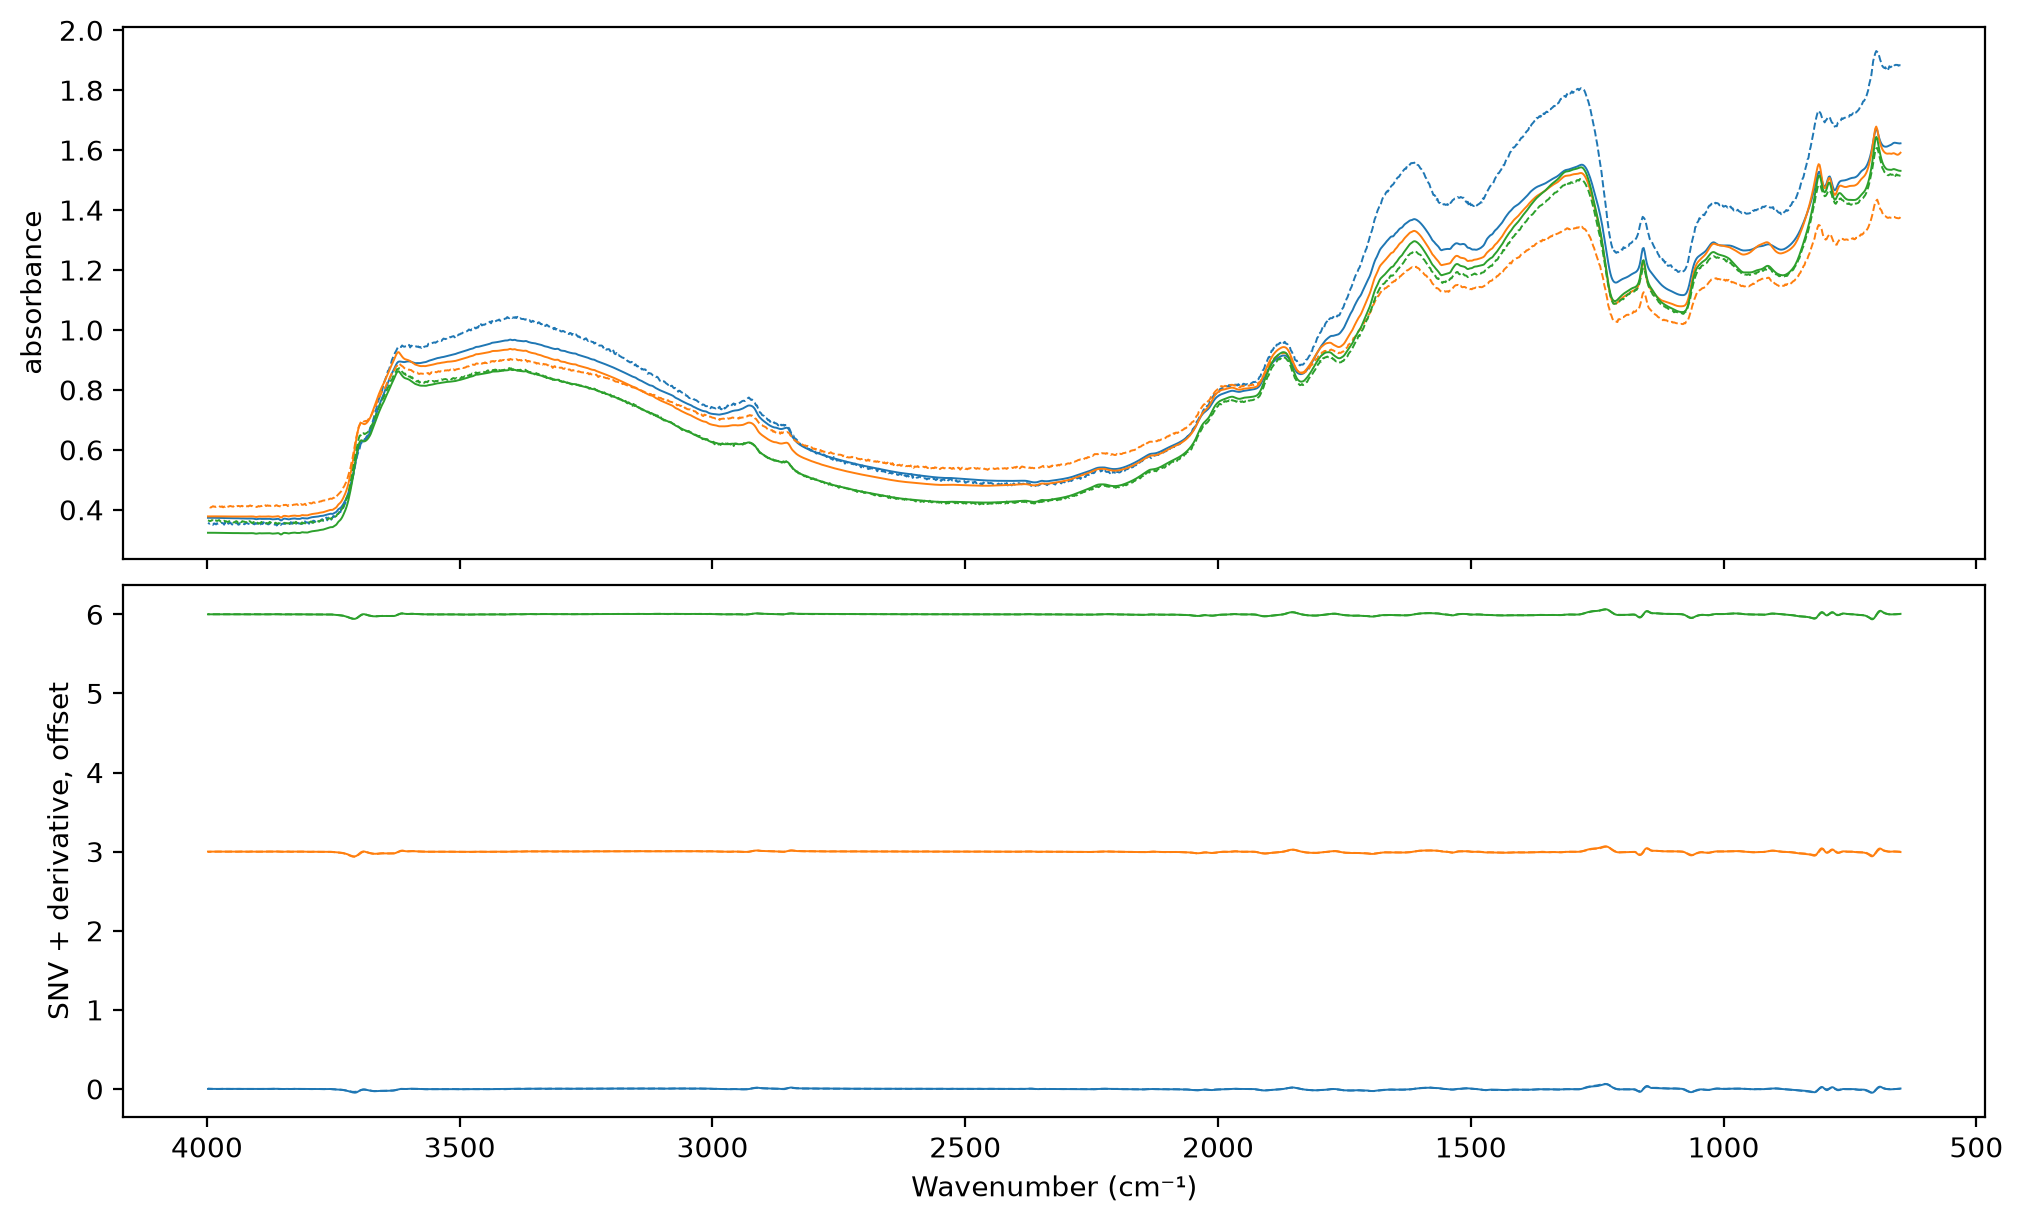

In [ ]:
#| fukudata
xs = TensorSpectrum(torch.tensor(Xo[:3], dtype=torch.float32).unsqueeze(1), wns=shared_wns)
set_seed(1)
xa = SpectralAug(p=1)(xs, split_idx=0)
sd = SNVDeriv(len(shared_wns))
fig, axs = plt.subplots(2, 1, figsize=(10, 6), sharex=True, layout='constrained')
for i in range(3):
    axs[0].plot(shared_wns, xs[i, 0], lw=0.7, c=f'C{i}'); axs[0].plot(shared_wns, xa[i, 0], lw=0.7, ls='--', c=f'C{i}')
    axs[1].plot(shared_wns, sd(xs)[i, 0] + 3 * i, lw=0.7, c=f'C{i}'); axs[1].plot(shared_wns, sd(xa)[i, 0] + 3 * i, lw=0.7, ls='--', c=f'C{i}')
axs[0].set_ylabel('absorbance'); axs[1].set_ylabel('SNV + derivative, offset'); axs[1].invert_xaxis(); axs[1].set_xlabel('Wavenumber (cm⁻¹)');

## Pretraining

The augmented model trains as the saved model `ossl_kex_snv_d1` did: the same split, seed and schedule (20 epochs, learning rate 10⁻³). The last epoch, with the OSSL validation R²:

In [ ]:
#| fukudata
models = {'no augmentation': load_pretrained('ossl_kex_snv_d1'), 'augmentation': pretrain_aug(Xo, yo, 'ossl_kex_aug', SpectralAug())}
pretrain_history('ossl_kex_aug').iloc[-1].round(3).to_dict()

{'train_loss': 0.028, 'valid_loss': 0.032, 'r2_score': 0.782}

## Fukushima

Zero-shot scores of both models on the Fukushima training and test samples:

In [ ]:
#| fukudata
pd.DataFrame({(m, s): scores(yf[msk], predict(model, Xf_d[msk])) for m, model in models.items()
              for s, msk in (('train', ~is_test), ('test', is_test))}).T.round(3)

R²      r   RMSE   bias
no augmentation train -0.748  0.162  0.597  0.305
                test  -0.820  0.126  0.537  0.285
augmentation    train -0.556 -0.027  0.584  0.133
                test  -0.707 -0.096  0.539  0.140

Ridge `probe`s on each frozen layer of both models, trained on the Fukushima training samples and scored on the test samples:

In [ ]:
#| fukudata
pr = {}
for m, model in models.items():
    Fm = layer_features(model, Xf_d)
    for k, Fk in Fm.items(): pr[m, k] = probe(Fk[~is_test], yf[~is_test], Fk[is_test], yf[is_test])
pd.DataFrame(pr).T[['R²', 'r']].unstack(0).round(3)

R²                            r                
        augmentation no augmentation augmentation no augmentation
block 1        0.381           0.378        0.619           0.618
block 2        0.409           0.403        0.640           0.635
block 3        0.420           0.396        0.649           0.629
block 4        0.432           0.429        0.660           0.657
block 5        0.387           0.371        0.626           0.614
input          0.332           0.332        0.582           0.582
pooled         0.313           0.253        0.563           0.504

## Findings

Augmentation during OSSL pretraining doesn't make the CNN transfer to Fukushima. The augmented model reaches an OSSL validation R² of 0.78, against 0.79 without augmentation. Its zero-shot correlation for Fukushima Kex is -0.10 on the test samples, against 0.13 without augmentation. Its bias is smaller (0.14 against 0.29 in `log1p` units), and R² is -0.71 against -0.82.

Ridge probes on its frozen layers give the same Kex scores as without augmentation, within the sampling noise of about 0.04. Block 4 gives R² 0.43 for both models. The largest differences are in block 3 (0.42 against 0.40) and the pooled features (0.31 against 0.25).

The perturbations cover the differences that `05_paired` measured between the Bruker and Thermo spectra: broadening, shift, contrast and baseline. A model trained to ignore them still fails on the Fukushima spectra. So these measured differences are not what separates the Fukushima spectra from OSSL for Kex, or the ranges used here are too small. This run tried one setting, with each perturbation applied with probability 0.5.

In [ ]:
#| hide
import nbdev; nbdev.nbdev_export()